# Phase 8: Portfolio KPIs, Loss Ratio, COR, ATP

**Business question this phase serves:** *"Segment X has a Loss Ratio above the rest of the book.
Should we reprice it?"* This notebook looks for that segment, and checks that a candidate is a real
pricing gap rather than noise before carrying it forward.

**KPI definitions used throughout:**
- **Loss Ratio (LR)** = incurred claims / earned premium
- **Combined Operating Ratio (COR)** = Loss Ratio + expense ratio
- **Average Technical Premium (ATP)** = mean annualized technical premium per policy

**Two assumptions (freMTPL2 has neither premium nor expense data):**
1. **"Earned premium" is the Phase 7 technical premium**, prorated to each policy's exposure. Loss Ratio
   therefore measures how well the model's expected cost matches actual claims, not realized profit.
2. **The expense ratio is a flat assumption (27%)**, in the range commonly cited for French personal
   motor; not fitted from data.

**What this notebook does, in order:**
1. Portfolio-level KPIs.
2. A first pass at Loss Ratio by region, which flags a large region.
3. A check of that flag: decomposing Loss Ratio into attritional and large-loss layers.
4. The segment search redone on the attritional layer, in and out of sample.
5. The large-loss layer by fuel type.
6. The segment carried forward into Phases 9-11, with its measured cost relativity.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scoring.score_technical_premium import TechnicalPremiumModel, score_technical_premium
from src.pricing.portfolio_kpis import add_earned_premium, compute_kpis, kpis_by_segment, DEFAULT_EXPENSE_RATIO
from src.eda.profiling import bin_continuous

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# The full portfolio (train + val + test): portfolio reporting covers the whole book. Section 4 also
# splits every result by train / validation / test, to separate in-sample from out-of-sample evidence.
df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "policy_level_clean.parquet")
tp_model = TechnicalPremiumModel.load(PROJECT_ROOT / "models")
scored = score_technical_premium(df, tp_model)
df = pd.concat([df.reset_index(drop=True), scored.reset_index(drop=True)], axis=1)
df = add_earned_premium(df)

print(f"Portfolio: {len(df):,} policies")
print(f"Assumed expense ratio: {DEFAULT_EXPENSE_RATIO:.0%}")

Portfolio: 668,626 policies
Assumed expense ratio: 27%


## 1. Portfolio-level KPIs

In [2]:
overall = compute_kpis(df)
for k, v in overall.items():
    print(f"{k:<24}: {v:,.4f}" if isinstance(v, float) else f"{k:<24}: {v:,}")

n_policies              : 668,626
total_exposure          : 353,559.9280
total_earned_premium    : 52,594,660.9321
total_incurred_claims   : 59,260,477.5000
loss_ratio              : 1.1267
expense_ratio           : 0.2700
cor                     : 1.3967
atp                     : 157.9941


**Reading:** on the whole portfolio, incurred claims are **112.7%** of the technical premium, and with
the 27% expense assumption the COR is 139.7%. This does not mean the technical premium is too low on
average: it reconciles with paid claims on the training set (99.7%) and the test set (98.3%), Phase 7.
The excess comes from the large-loss layer in the validation set, which holds the largest claims of the
dataset (EUR 4.08M among them, Phase 3). The next sections separate that layer from the attritional one
before judging any segment.

## 2. First pass: Loss Ratio by region

The most natural first cut: geography. Sorted worst (highest LR) to best.

In [3]:
region_kpis = kpis_by_segment(df, "Region")
region_kpis.head(10)

,Region,n_policies,exposure_share,total_exposure,total_earned_premium,total_incurred_claims,loss_ratio,expense_ratio,cor,atp
0,R21,2947,0.0033,"1,182.5351","218,559.1439","478,199.3600",2.1880,0.2700,2.4580,188.7149
1,R24,157959,0.2848,"100,684.5760","12,806,374.7932","18,793,281.6900",1.4675,0.2700,1.7375,135.6814
2,R82,83975,0.1272,"44,985.2735","8,077,917.3483","10,248,720.6900",1.2687,0.2700,1.5387,188.1811
3,R22,7871,0.0100,"3,536.9938","589,304.1571","682,779.6900",1.1586,0.2700,1.4286,171.5204
4,R94,4404,0.0049,"1,729.9372","408,361.3544","464,255.9800",1.1369,0.2700,1.4069,240.9557
5,R42,2159,0.0034,"1,193.2758","108,759.7561","121,424.9900",1.1165,0.2700,1.3865,94.9504
6,R41,12851,0.0228,"8,069.1180","971,896.1353","1,026,612.5900",1.0563,0.2700,1.3263,127.1033
7,R25,10704,0.0185,"6,530.3275","875,753.5714","915,823.2500",1.0458,0.2700,1.3158,140.8516
8,R53,41303,0.0768,"27,148.3745","3,699,440.9863","3,791,926.6900",1.0250,0.2700,1.2950,142.4535
9,R93,78421,0.1003,"35,473.6590","6,811,265.0994","6,832,981.0500",1.0032,0.2700,1.2732,197.5341


**A material-looking problem, at first glance:** `R21` has the worst LR (218.8%) but is tiny (0.33% of
exposure), the kind of low-credibility noise Phases 2 and 4 flagged. **`R24` is the more concerning
one**: LR **146.7%**, COR **173.8%**, on **28.5% of the portfolio's exposure**, the largest region by
far. On these numbers `R24` looks like the segment the business question describes. The next section
checks whether that holds.

## 3. Is `R24`'s Loss Ratio a pricing gap, or large-loss noise?

Phase 6 built the large-loss loading (EUR 33.54 per policy-year) as a **flat, portfolio-wide** charge,
because large losses are too sparse to attribute to a segment. Judging that flat charge segment by
segment is therefore the wrong check: a segment that happens to contain a few very large claims will
show a high Loss Ratio without being underpriced. `R24` is checked against this first.

In [4]:
sev_glm_artifact = joblib.load(PROJECT_ROOT / "models" / "sev_glm.pkl")
threshold = sev_glm_artifact["large_loss_threshold"]  # Phase 6's large-loss threshold, EUR: loaded, not retyped
print(f"Large-loss threshold (Phase 6): EUR {threshold:,.2f}")

df["capped_claims"] = np.minimum(df["sev_claim_amount"], threshold * df["sev_claim_count"].clip(lower=1))
df["large_loss_excess"] = df["sev_claim_amount"] - df["capped_claims"]
df["attritional_premium"] = df["predicted_frequency"] * df["predicted_severity"] * df["Exposure"]

r24 = df[df["Region"] == "R24"]
rest = df[df["Region"] != "R24"]

for name, g in [("R24", r24), ("Rest of portfolio", rest)]:
    full_lr = g["sev_claim_amount"].sum() / (g["attritional_premium"].sum() + g["Exposure"].sum() * tp_model.large_loss_loading)
    attritional_lr = g["capped_claims"].sum() / g["attritional_premium"].sum()
    large_loss_share = g["large_loss_excess"].sum() / g["sev_claim_amount"].sum()
    print(f"{name:<20} full LR={full_lr:.1%}   attritional-only LR={attritional_lr:.1%}   share of claims from large losses={large_loss_share:.1%}")

print(f"\nSingle largest claim in the whole dataset: EUR {df['sev_claim_amount'].max():,.0f}: located in Region: {df.loc[df['sev_claim_amount'].idxmax(), 'Region']}")

Large-loss threshold (Phase 6): EUR 15,000.00
R24                  full LR=146.7%   attritional-only LR=100.8%   share of claims from large losses=49.4%
Rest of portfolio    full LR=101.7%   attritional-only LR=100.5%   share of claims from large losses=22.2%

Single largest claim in the whole dataset: EUR 4,075,401: located in Region: R24


**Finding: the first-pass conclusion does not hold.** On the attritional layer (claims capped at
EUR 15,000), `R24`'s Loss Ratio (**100.8%**) is the same as the rest of the portfolio's (**100.5%**).
Its high raw LR comes from large losses (49.4% of its claim cost, against 22.2% elsewhere), including the
largest claim in the dataset (EUR 4.08M). Repricing `R24` on its raw LR would have been a mistake.

## 4. Redoing the search on the attritional layer, in and out of sample

The fair version of Section 2: each segment's claims capped at the large-loss threshold, compared with
the matching attritional premium (frequency x severity, without the flat large-loss loading). The
result is shown as an actual-to-expected ratio relative to the book (A/E = 1.00 means the segment is
priced in line with the rest of the portfolio).

A gap only counts as a pricing signal if it holds out of sample. The models were fitted on the
training set only, so the same ratio is also computed on the validation and test sets separately: a
real mispricing shows up in all three, noise does not.

In [5]:
from src.data.load_data import load_sev_raw

# Which split each policy belongs to (Phase 3), to separate in-sample from out-of-sample evidence.
split_of = pd.concat(
    [pd.read_parquet(PROJECT_ROOT / "data" / "processed" / f"{s}.parquet", columns=["IDpol"]).assign(split=s)
     for s in ["train", "val", "test"]]
)
df = df.merge(split_of, on="IDpol", how="left")

# Number of individual claims above the large-loss threshold, per policy.
sev_raw = load_sev_raw()
n_large = (sev_raw.assign(is_large=sev_raw["ClaimAmount"] > threshold)
           .groupby("IDpol")["is_large"].sum().rename("n_large_claims"))
df = df.merge(n_large, left_on="IDpol", right_index=True, how="left")
df["n_large_claims"] = df["n_large_claims"].fillna(0).astype(int)

# Banded versions of the continuous rating factors.
df["BonusMalus_band"] = pd.cut(df["BonusMalus"], [0, 50, 60, 80, 100, 1000],
                               labels=["50", "51-60", "61-80", "81-100", ">100"])
df["DrivAge_band"] = pd.cut(df["DrivAge"], [17, 25, 35, 50, 65, 120],
                            labels=["18-25", "26-35", "36-50", "51-65", "66+"])
df["VehAge_band"] = pd.cut(df["VehAge"], [-1, 1, 4, 10, 200], labels=["0-1", "2-4", "5-10", "11+"])


def attritional_ae(d: pd.DataFrame) -> float:
    return d["capped_claims"].sum() / d["attritional_premium"].sum()


def attritional_ae_table(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Attritional A/E relative to the book: whole portfolio, validation set, test set."""
    book = {s: attritional_ae(df if s == "all" else df[df["split"] == s]) for s in ["all", "val", "test"]}
    rows = []
    for level, g in df.groupby(col, observed=True):
        row = {col: level,
               "exposure_share": g["Exposure"].sum() / df["Exposure"].sum(),
               "paid_claims": int(g["sev_claim_count"].sum())}
        for s in ["all", "val", "test"]:
            gs = g if s == "all" else g[g["split"] == s]
            row[f"AE_{s}"] = attritional_ae(gs) / book[s]
        rows.append(row)
    return pd.DataFrame(rows)


ae_tables = {}
fmt = {"exposure_share": "{:.1%}".format, "AE_all": "{:.2f}".format,
       "AE_val": "{:.2f}".format, "AE_test": "{:.2f}".format}
for col in ["VehGas", "BonusMalus_band", "DrivAge_band", "VehAge_band", "Area", "Region", "VehBrand"]:
    t = attritional_ae_table(df, col)
    ae_tables[col] = t
    large_levels_only = col in ("Region", "VehBrand")
    shown = t[t["exposure_share"] >= 0.03] if large_levels_only else t
    print(f"\n=== {col} ===" + ("  (levels with at least 3% of exposure)" if large_levels_only else ""))
    print(shown.to_string(index=False, formatters=fmt))


=== VehGas ===
 VehGas exposure_share  paid_claims AE_all AE_val AE_test
 Diesel          47.8%        13339   1.02   1.03    1.03
Regular          52.2%        12798   0.98   0.97    0.97



=== BonusMalus_band ===
BonusMalus_band exposure_share  paid_claims AE_all AE_val AE_test
             50          62.7%        11406   0.89   0.86    0.88
          51-60          13.4%         3537   1.21   1.15    1.22
          61-80          14.9%         5861   1.22   1.21    1.25
         81-100           8.0%         4080   0.93   1.05    0.96
           >100           1.0%         1253   0.98   1.05    0.87



=== DrivAge_band ===
DrivAge_band exposure_share  paid_claims AE_all AE_val AE_test
       18-25           4.5%         2392   1.01   1.13    1.04
       26-35          19.4%         5135   0.99   1.01    1.02
       36-50          36.9%         9574   1.01   1.01    1.00
       51-65          26.9%         6482   0.99   0.93    1.00
         66+          12.2%         2554   1.01   1.00    0.92



=== VehAge_band ===
VehAge_band exposure_share  paid_claims AE_all AE_val AE_test
        0-1          13.6%         3421   0.98   1.03    1.00
        2-4          22.2%         5843   1.04   1.02    1.02
       5-10          33.8%         9582   1.00   0.96    1.00
        11+          30.3%         7291   0.99   1.01    0.98



=== Area ===
Area exposure_share  paid_claims AE_all AE_val AE_test
   A          17.2%         3303   0.98   0.92    0.97
   B          12.0%         2599   1.02   1.01    1.03
   C          29.1%         7005   0.96   0.91    1.04
   D          21.6%         6403   1.03   1.08    0.96
   E          17.9%         6070   1.03   1.06    1.03
   F           2.3%          757   0.91   0.98    0.82



=== Region ===  (levels with at least 3% of exposure)
Region exposure_share  paid_claims AE_all AE_val AE_test
   R11           8.4%         2553   1.09   1.16    1.09
   R24          28.5%         6371   1.00   1.00    1.02
   R31           3.2%          941   1.07   1.21    1.10
   R52           6.1%         1565   1.05   1.12    0.86
   R53           7.7%         1832   1.00   0.95    1.02
   R54           3.1%          794   1.01   1.04    0.94
   R72           4.0%         1045   0.93   0.98    0.89
   R82          12.7%         4209   0.99   1.00    1.04
   R91           4.1%         1056   0.91   0.88    0.93
   R93          10.0%         2963   0.96   0.84    0.99



=== VehBrand ===  (levels with at least 3% of exposure)
VehBrand exposure_share  paid_claims AE_all AE_val AE_test
      B1          26.6%         6823   0.99   0.96    0.99
     B12          17.9%         4112   0.97   0.97    0.98
      B2          26.5%         6734   0.99   1.05    0.95
      B3           8.0%         2409   1.02   1.05    0.99
      B4           3.9%         1090   1.00   1.04    0.92
      B5           5.6%         1647   1.02   0.82    1.19
      B6           4.4%         1242   1.07   1.20    0.96


**Reading:** most factors sit close to 1.00, and where a level moves away from it, the direction often
changes between validation and test (for example `VehBrand` B5: 0.82 then 1.19), which is noise.

One factor stands out: **`BonusMalus`**. The bands 51-60 and 61-80 (28.3% of exposure together) cost
**15% to 25% more** than their technical premium predicts, relative to the book, in the training data
and again in the validation and test sets (1.21/1.15/1.22 and 1.22/1.21/1.25), while the bonus floor
(`50`, 62.7% of exposure) costs about 12% less. A signal that repeats on two independent held-out sets,
on thousands of claims per band, is a pricing gap, not chance.

`Region` R11 (8.4% of exposure, 1.09/1.16/1.09) is a smaller, secondary candidate. `VehGas` shows a
small residual (Diesel 1.02-1.03), well inside what the next section's large-loss view puts in
perspective.

### The large-loss layer by fuel type

The attritional view leaves one question open: could a difference between Diesel and Regular sit in the large losses instead? The next cell counts large claims and measures their cost per policy-year, separately on each split.

In [6]:
# The large-loss layer by fuel type: number of large claims and large-loss cost per policy-year,
# split by split, to see whether a difference in large losses is stable or driven by a few claims.
rows = []
for s in ["train", "val", "test"]:
    d = df[df["split"] == s]
    for gas, g in d.groupby("VehGas", observed=True):
        expo = g["Exposure"].sum()
        rows.append({
            "split": s,
            "VehGas": gas,
            "exposure_share": expo / d["Exposure"].sum(),
            "large_claims": int(g["n_large_claims"].sum()),
            "large_claims_per_1000_years": 1000 * g["n_large_claims"].sum() / expo,
            "large_loss_EUR_per_policy_year": g["large_loss_excess"].sum() / expo,
        })
large_by_gas = pd.DataFrame(rows)
print(large_by_gas.to_string(index=False, formatters={
    "exposure_share": "{:.1%}".format,
    "large_claims_per_1000_years": "{:.2f}".format,
    "large_loss_EUR_per_policy_year": "{:,.1f}".format,
}))
print(f"\nFlat large-loss loading charged to every policy (Phase 6): EUR {tp_model.large_loss_loading:,.2f} per policy-year")

split  VehGas exposure_share  large_claims large_claims_per_1000_years large_loss_EUR_per_policy_year
train  Diesel          47.6%            80                        0.79                           38.4
train Regular          52.4%            81                        0.73                           29.1
  val  Diesel          47.8%            31                        0.92                           34.3
  val Regular          52.2%            36                        0.97                          214.5
 test  Diesel          48.1%            31                        0.91                           40.3
 test Regular          51.9%            34                        0.93                           19.2

Flat large-loss loading charged to every policy (Phase 6): EUR 33.54 per policy-year


**Reading:** Diesel and Regular have **the same rate of large claims** (0.7-1.0 per 1,000
policy-years in every split). What differs is the *cost* of those claims, and its direction flips from
one split to the next: higher for Diesel in train and test, but EUR 214 per policy-year for Regular in
validation, where a few very large claims fell. That is driven by a handful of individual claims, not by
fuel type, which is why the large-loss layer is charged flat to every policy. Fuel type is not a
repricing candidate.

## 5. Segment X, for Phase 9-11

**`BonusMalus` 51-80** is the segment carried forward as "Segment X": 28.3% of exposure, a gap on the
attritional layer that holds out of sample, and a mechanism that explains it. The frequency GLM treats
`BonusMalus` as a single straight line on the log scale (Phase 4, kept in Phase 7), while the Phase 5
GAM showed a curve that rises steeply from 50 to about 70 and then flattens. A straight line through
that curve under-predicts the middle of the range and over-predicts the bonus floor, which is exactly
the pattern above.

The cell below measures the segment's expected cost relative to the book on the validation and test
sets only: attritional claims from the segment's own experience, large losses charged at the book
average rate. The indicated price change is that relativity minus one.

In [7]:
from src.pricing.portfolio_kpis import experience_cost_factor
from src.pricing.segment_x import in_segment_x, save_segment_x

segment_x = {"column": "BonusMalus", "low": 51, "high": 80, "label": "BonusMalus 51-80"}

# Expected cost as a multiple of the technical premium, measured out of sample (validation + test):
# attritional claims from the segment's own experience, large losses at the flat loading (Phase 6).
oos = df[df["split"].isin(["val", "test"])]
seg_oos = oos[in_segment_x(oos, segment_x)]
factor_segment = experience_cost_factor(seg_oos, threshold)
factor_book = experience_cost_factor(oos, threshold)
cost_relativity = factor_segment / factor_book

segment_x.update({
    "exposure_share": float(df.loc[in_segment_x(df, segment_x), "Exposure"].sum() / df["Exposure"].sum()),
    "cost_relativity": float(cost_relativity),
    "indicated_price_change": float(round(cost_relativity - 1, 2)),
    "measured_on": "validation + test sets (out of sample)",
})
path = save_segment_x(segment_x, PROJECT_ROOT)

attritional_relativity = attritional_ae(seg_oos) / attritional_ae(oos)

print(f"Segment X                                    : {segment_x['label']}")
print(f"Share of portfolio exposure                  : {segment_x['exposure_share']:.1%}")
print(f"Attritional A/E vs. book (validation + test) : {attritional_relativity:.3f}")
print(f"Cost relativity vs. book, flat large losses  : {cost_relativity:.3f}")
print(f"Indicated price change                       : {segment_x['indicated_price_change']:+.0%}")
print(f"Saved: {path.relative_to(PROJECT_ROOT).as_posix()}")

Segment X                                    : BonusMalus 51-80
Share of portfolio exposure                  : 28.3%
Attritional A/E vs. book (validation + test) : 1.211
Cost relativity vs. book, flat large losses  : 1.166
Indicated price change                       : +17%
Saved: reports/figures/segment_x.json


### Mechanism check: does a binned `BonusMalus` close the gap?

If the gap comes from the straight-line `BonusMalus` term, replacing that term by bands in the Phase 7
refined GLM (same 40% training sub-sample, everything else unchanged) should improve the out-of-sample
fit. A check only: the tariff in force keeps the linear term, and the correction is applied in Phase 11.

In [8]:
from sklearn.model_selection import train_test_split
from src.features.pipeline import get_exposure_offset, get_frequency_target
from src.models.frequency_glm import fit_poisson_glm
from src.models.frequency_glm_refined import RefinedFeatureEncoder
from src.models.glm_diagnostics import out_of_sample_pseudo_r2
import statsmodels.api as sm

train_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")
val_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "val.parquet")
bucket = pd.cut(train_df["ClaimNb_freq_target"], bins=[-1, 0, 1, np.inf], labels=["0", "1", "2+"])
train_sub, _ = train_test_split(train_df, train_size=0.40, stratify=bucket, random_state=42)  # as in Phase 7
train_sub = train_sub.reset_index(drop=True)
refined_encoder = RefinedFeatureEncoder().fit(train_sub)

BM_EDGES = [0, 50, 60, 70, 80, 90, 100, 1000]


def with_bm_bands(frame):
    X = refined_encoder.transform(frame).drop(columns=["BonusMalus"]).reset_index(drop=True)
    bands = pd.get_dummies(pd.cut(frame["BonusMalus"], BM_EDGES, labels=False), prefix="BM", drop_first=True).astype(float)
    return pd.concat([X, bands.reset_index(drop=True)], axis=1)


results = {}
for name, build in [("refined GLM, linear BonusMalus", refined_encoder.transform), ("refined GLM, BonusMalus bands", with_bm_bands)]:
    fit = fit_poisson_glm(build(train_sub), get_frequency_target(train_sub), get_exposure_offset(train_sub))
    X_val = sm.add_constant(build(val_df), has_constant="add")
    pred = fit.predict(X_val, offset=get_exposure_offset(val_df))
    results[name] = out_of_sample_pseudo_r2(get_frequency_target(val_df).to_numpy(), pred, val_df["Exposure"].to_numpy())["pseudo_r2"]
    print(f"{name:<34}: validation pseudo-R^2 {results[name]:.2%}")
print("GAM (Phase 5), for reference      : validation pseudo-R^2 5.49%")

refined GLM, linear BonusMalus    : validation pseudo-R^2 4.72%


refined GLM, BonusMalus bands     : validation pseudo-R^2 5.28%
GAM (Phase 5), for reference      : validation pseudo-R^2 5.49%


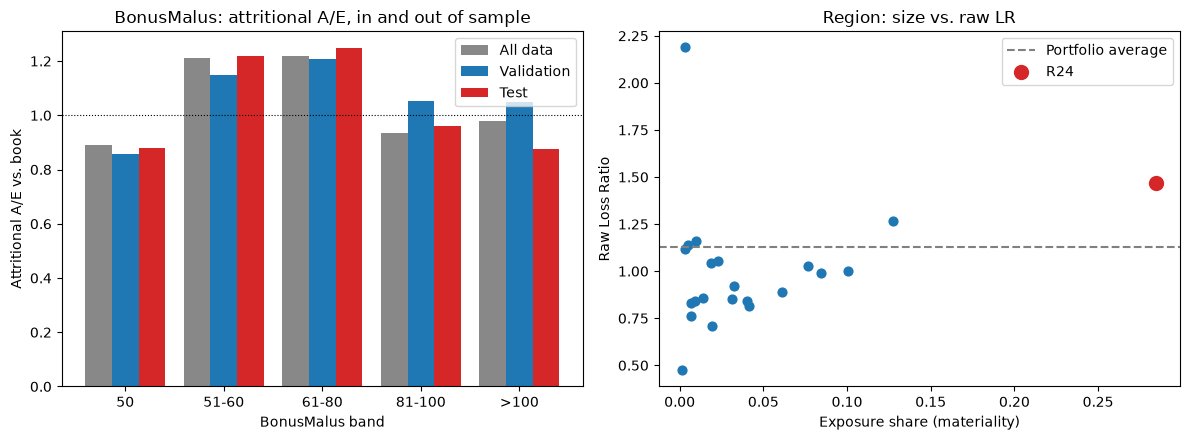

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bm = ae_tables["BonusMalus_band"]
x = np.arange(len(bm))
width = 0.27
labels = {"all": "All data", "val": "Validation", "test": "Test"}
for i, (s, colr) in enumerate([("all", "#888888"), ("val", "#1f77b4"), ("test", "#d62728")]):
    axes[0].bar(x + (i - 1) * width, bm[f"AE_{s}"], width, label=labels[s], color=colr)
axes[0].axhline(1.0, color="black", linewidth=0.8, linestyle=":")
axes[0].set_xticks(x)
axes[0].set_xticklabels(bm["BonusMalus_band"])
axes[0].set_xlabel("BonusMalus band")
axes[0].set_ylabel("Attritional A/E vs. book")
axes[0].set_title("BonusMalus: attritional A/E, in and out of sample")
axes[0].legend()

region_plot = region_kpis.copy()
axes[1].scatter(region_plot["exposure_share"], region_plot["loss_ratio"], s=40, color="#1f77b4")
axes[1].axhline(overall["loss_ratio"], color="gray", linestyle="--", label="Portfolio average")
r24_row = region_plot[region_plot["Region"] == "R24"]
axes[1].scatter(r24_row["exposure_share"], r24_row["loss_ratio"], s=100, color="#d62728", label="R24", zorder=5)
axes[1].set_xlabel("Exposure share (materiality)")
axes[1].set_ylabel("Raw Loss Ratio")
axes[1].set_title("Region: size vs. raw LR")
axes[1].legend()

fig.tight_layout()
plt.show()

## 6. Save the KPI tables

In [10]:
reports_dir = PROJECT_ROOT / "reports" / "figures"
reports_dir.mkdir(parents=True, exist_ok=True)
region_kpis.to_csv(reports_dir / "kpis_by_region.csv", index=False)
pd.concat([t.rename(columns={c: "level"}).assign(factor=c) for c, t in ae_tables.items()]).to_csv(
    reports_dir / "attritional_ae_by_segment.csv", index=False
)
large_by_gas.to_csv(reports_dir / "large_losses_by_vehgas.csv", index=False)
print("Saved: reports/figures/kpis_by_region.csv, attritional_ae_by_segment.csv, large_losses_by_vehgas.csv")

Saved: reports/figures/kpis_by_region.csv, attritional_ae_by_segment.csv, large_losses_by_vehgas.csv


## Phase 8 summary

| Check | Result |
|---|---|
| Portfolio LR / COR / ATP (all data) | 112.7% / 139.7% / EUR 158 per policy-year; the excess over 100% comes from large losses in the validation set |
| First-pass (raw) segment scan | `R24` looked like a major problem: LR 146.7%, COR 173.8%, 28.5% of exposure |
| Check applied | Raw LR by segment is the wrong test for a flat large-loss charge: decomposed into attritional and large-loss layers |
| `R24`, checked | Attritional LR 100.8% vs. 100.5% for the rest: no pricing gap; the raw number comes from large losses |
| Attritional A/E by segment, in and out of sample | Only `BonusMalus` 51-80 shows a large gap that repeats on validation and test (about +15% to +25%) |
| Fuel type | Same large-claim rate for Diesel and Regular; large-loss cost flips direction between splits: not a repricing candidate |
| Mechanism | Linear `BonusMalus` term vs. the concave curve found by the Phase 5 GAM; binning `BonusMalus` raises validation pseudo-R² from 4.72% to 5.28% |
| **Segment X for Phase 9-11** | `BonusMalus` 51-80, 28.3% of exposure; out-of-sample cost relativity 1.17, indicated price change **+17%** |

**Output:** [`reports/figures/kpis_by_region.csv`](../reports/figures/kpis_by_region.csv),
[`reports/figures/attritional_ae_by_segment.csv`](../reports/figures/attritional_ae_by_segment.csv),
[`reports/figures/large_losses_by_vehgas.csv`](../reports/figures/large_losses_by_vehgas.csv),
[`reports/figures/segment_x.json`](../reports/figures/segment_x.json), ready for **Phase 9: retention
model**.